# Regridding: 2 m temperature on a 200 m grid over Valais

This example illustrates {func}`~grid_process.grid_interp.interp2grid` with four methods:

- `nearest`: value of the nearest source grid point;
- `linear`: linear interpolation (bilinear on regular grids, on a triangulation for unstructured grids);
- `idw`: inverse distance weighting of the `k` nearest grid points, with weights `d^(-weight_power)`;
- `temp_fixgrad`: among the source grid points within `r_search` grid spacings, the one with the most
  similar altitude, corrected for the remaining altitude difference with a fixed lapse rate
  (6 K/km by default).

The 2 m temperature of IFS-HRES (regular 0.1° grid, about 9 km) and of the ICON-CH2 control member
(unstructured grid, about 2 km) is regridded to the 200 m digital height model of swisstopo over
Valais, a region of deep valleys and high mountains, for the same valid time.

*Data: ECMWF open data, © ECMWF, CC BY 4.0. MeteoSwiss open data, CC BY 4.0, source: MeteoSwiss.
DHM25/200, © swisstopo. Country borders: Natural Earth.*

In [1]:
import datetime as dt
import logging
import os
import re
import time
import timeit
import zipfile
from collections.abc import Callable
from functools import partial
from typing import Any

# import pyproj before earthkit.data to avoid a crash at exit (earthkit-data#1202)
import pyproj  # noqa: F401  # pylint: disable=unused-import
import eccodes_cosmo_resources

# ICON GRIB files need the COSMO definitions of ecCodes
os.environ["ECCODES_DEFINITION_PATH"] = str(eccodes_cosmo_resources.get_definitions_path())
os.environ["ECCODES_VERSION_CHECK_OFF"] = "1"
# no download progress bars: for ICON they would show the signed download URLs
os.environ["TQDM_DISABLE"] = "1"

import cartopy.crs as ccrs
import earthkit.data as ekd
import earthkit.plots as ekp
import geopandas as gpd
import numpy as np
import pandas as pd
import requests
import xarray as xr
from earthkit.data.utils import download_and_cache
from requests.adapters import HTTPAdapter
from urllib3.util import Retry

import grid_process.grid_interp as gri
import grid_process.timeseries as tms
import grid_process.units_conv as uconv
from grid_process import data_model as dm

METHODS: dict[str, dict[str, Any]] = {
    "nearest": {"method": "nearest"},
    "linear": {"method": "linear"},
    "idw": {"method": "idw", "k": 4, "weight_power": 2},
    "temp_fixgrad": {"method": "temp_fixgrad"},
}
LEAD_H_IFS = 24  # lead time [h] of the latest IFS-HRES run defining the common valid time

## Destination grid

The DHM25/200 height model of swisstopo is an ESRI ASCII grid in the former Swiss coordinate system
LV03 (EPSG:21781), which the file does not state. We read it from the zip file into a dataset with 1D `x`/`y` coordinates of the pixel centres, the CRS in
the `crs` attribute and the altitude in a `surface_altitude` coordinate, which `temp_fixgrad` needs.
The subregion covers Valais and its surroundings, from Lausanne to the Gotthard and from the Bernese
Oberland to the Italian border (496 × 833 cells).

In [2]:
DHM_URL = "https://data.geo.admin.ch/ch.swisstopo.digitales-hoehenmodell_25/data.zip"


def read_dhm25(zip_path: str) -> xr.Dataset:
    """Read the 200 m grid of the DHM25 zip file of swisstopo.

    DHM200.asc is an ESRI ASCII grid (rows wrapped over several lines) in the former Swiss coordinate system
    LV03 (EPSG:21781), which the zip file does not state (no .prj file).
    """
    with zipfile.ZipFile(zip_path) as archive, archive.open("DHM200.asc") as f:
        header = {key.lower(): float(value) for key, value in (f.readline().decode().split() for _ in range(6))}
        nrows, ncols = int(header["nrows"]), int(header["ncols"])
        values = np.array(f.read().split(), dtype="float32").reshape(nrows, ncols)
    values[values == header["nodata_value"]] = np.nan
    size = header["cellsize"]
    x = header["xllcorner"] + size * (np.arange(ncols) + 0.5)
    y = header["yllcorner"] + size * (np.arange(nrows)[::-1] + 0.5)  # first row is the northernmost
    return xr.Dataset(
        coords={"x": x, "y": y, "surface_altitude": (("y", "x"), values, {"units": "m"})}, attrs={"crs": "EPSG:21781"}
    )


# the zip file is downloaded once into the earthkit cache
dst_grid = read_dhm25(download_and_cache(DHM_URL)).sel(x=slice(532800, 699200), y=slice(174000, 75000))
dst_grid

<xarray.Dataset> Size: 2MB
Dimensions:           (x: 833, y: 496)
Coordinates:
  * x                 (x) float64 7kB 5.328e+05 5.33e+05 ... 6.99e+05 6.992e+05
    surface_altitude  (y, x) float32 2MB 439.6 439.8 441.8 441.2 ... nan nan nan
  * y                 (y) float64 4kB 1.74e+05 1.738e+05 ... 7.52e+04 7.5e+04
Data variables:
    *empty*
Attributes:
    crs:      EPSG:21781

## Source data

The common valid time is the latest IFS-HRES run + `LEAD_H_IFS`. For ICON-CH2 we take the oldest run
still on the MeteoSwiss portal, which is always complete, at the lead time reaching the same valid
time. Each model comes with its own orography for `temp_fixgrad`: the surface geopotential `z` at step
0 for IFS, `HSURF` for ICON. IFS open data are global fields, cropped right after loading with a wide
margin. ICON files cover the full model domain; `interp2grid` itself restricts the source data to the
destination domain.

In [3]:
OD_ROOT = "https://data.ecmwf.int/forecasts"
IFS_BBOX = {"latitude": slice(47.5, 45.0), "longitude": slice(5.5, 10.0)}  # Valais with a wide margin

# the portal sometimes times out: retry with an increasing delay (earthkit already retries the field downloads)
session = requests.Session()
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retry))
# hide the notice about the connection limit of the portal that the ECMWF open data client logs
logging.getLogger("ecmwf.opendata.utils").addFilter(lambda record: "500 simultaneous" not in record.getMessage())


def index_url(day: str, hour: int, step: int) -> str:
    return f"{OD_ROOT}/{day}/{hour:02d}z/ifs/0p1/oper/{day}{hour:02d}0000-{step}h-oper-fc-sfc.index"


def list_days() -> list[str]:
    """Days with forecasts on the portal, oldest first."""
    return sorted(set(re.findall(r'href="/forecasts/(\d{8})/"', session.get(f"{OD_ROOT}/", timeout=30).text)))


def latest_ifs_run(step: int) -> tuple[str, int]:
    """Latest IFS-HRES run on the ECMWF open data portal with the given step already published."""
    for day in reversed(list_days()):
        for hour in (18, 12, 6, 0):
            if session.head(index_url(day, hour, step), timeout=30).ok:
                return day, hour
    raise RuntimeError("No IFS-HRES run found on the open data portal")


def open_ifs(**request: Any) -> ekd.FieldList:
    return ekd.from_source(
        "ecmwf-open-data",
        model="ifs",
        resol="0p1",
        stream="oper",
        type="fc",
        date=int(run_date),
        time=run_hour,
        **request,
    ).to_fieldlist()


run_date, run_hour = latest_ifs_run(LEAD_H_IFS)
ds_ifs = open_ifs(param="2t", step=LEAD_H_IFS).to_xarray(time_dims=["forecast_reference_time", "step"], squeeze=False)
# with the COSMO definitions of ecCodes (set above for ICON) the IFS fields get COSMO names: take the single variable
ds_ifs = ds_ifs.squeeze(["level", "level_type"], drop=True).sel(IFS_BBOX)
ds_ifs = ds_ifs.rename({next(iter(ds_ifs.data_vars)): "T_2M"})
ds_z = open_ifs(param="z", levtype="sfc", step=0).to_xarray()
z_surf = next(iter(ds_z.data_vars.values())).squeeze().reset_coords(drop=True).sel(IFS_BBOX)
ds_ifs = ds_ifs.assign_coords(surface_altitude=(z_surf / 9.80665).astype("float32")).astype("float32")
valid_time = pd.Timestamp(ds_ifs.forecast_reference_time.item()) + pd.Timedelta(hours=LEAD_H_IFS)
print(f"IFS-HRES run {run_date} {run_hour:02d} UTC, valid time {valid_time} UTC")

IFS-HRES run 20261028 12 UTC, valid time 2026-10-29 12:00:00 UTC


In [4]:
COLLECTION = "ogd-forecasting-icon-ch2"


def oldest_icon_run(variable: str, margin: dt.timedelta = dt.timedelta(minutes=30)) -> str:
    """Oldest run whose first lead time (uploaded, hence deleted, first) is still available."""
    response = requests.post(
        "https://data.geo.admin.ch/api/stac/v1/search",
        json={
            "collections": [f"ch.meteoschweiz.{COLLECTION}"],
            "forecast:variable": variable,
            "forecast:perturbed": False,
            "forecast:horizon": "P0DT00H00M00S",
            "sortby": [{"field": "properties.datetime", "direction": "asc"}],
        },
        timeout=30,
    )
    now = dt.datetime.now(dt.timezone.utc)
    for item in response.json()["features"]:
        if dt.datetime.fromisoformat(item["properties"]["expires"]) > now + margin:
            return item["properties"]["forecast:reference_datetime"]
    raise RuntimeError("No run found on the open data portal")


ref_time = oldest_icon_run("T_2M")
lead_h = int((valid_time - pd.Timestamp(ref_time).tz_convert(None)) / pd.Timedelta(hours=1))
print(f"ICON-CH2 run {ref_time}, lead time {lead_h} h")

ds_icon = ekd.from_source(
    "meteoswiss-opendata",
    collection=COLLECTION,
    variable="T_2M",
    ref_time=ref_time,
    perturbed=False,
    lead_time=[f"P0DT{lead_h}H"],
).to_xarray(time_dims=["forecast_reference_time", "step"], squeeze=False)
ds_icon = ds_icon.squeeze(["member", "level", "level_type"], drop=True).rename_dims(values="cell")
constants = ekd.from_source("meteoswiss-opendata-constants", collection=COLLECTION, asset="horizontal")
hsurf = constants.to_fieldlist().sel({"parameter.variable": "HSURF"})[0].to_numpy()
ds_icon = ds_icon.assign_coords(HSURF=("cell", hsurf.astype("float32"))).astype("float32")

models = {}
for name, ds in {"IFS-HRES": ds_ifs, "ICON-CH2": ds_icon}.items():
    ds = tms.setindex_validtime(ds.load())  # forecast_reference_time and step -> time
    models[name] = uconv.ds_to(ds, {"T_2M": "degC"})
models["ICON-CH2"]

ICON-CH2 run 2026-10-28T00:00:00Z, lead time 36 h


<xarray.Dataset> Size: 7MB
Dimensions:                  (time: 1, cell: 283876)
Coordinates:
  * time                     (time) datetime64[us] 8B 2026-10-29T12:00:00
    forecast_reference_time  (time) datetime64[us] 8B 2026-10-28
    latitude                 (cell) float64 2MB 46.97 46.98 ... 50.06 50.05
    longitude                (cell) float64 2MB -0.1542 -0.1638 ... 12.83 12.81
    HSURF                    (cell) float32 1MB 94.11 87.99 ... 626.5 682.7
Dimensions without coordinates: cell
Data variables:
    T_2M                     (time, cell) float32 1MB 8.086 8.004 ... 10.3 9.756
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Interpolation

Each method is called once per model, and the duration of this first call is kept for the benchmark
below. DHM25/200 has no altitude in parts of the box outside Switzerland, where `temp_fixgrad` returns
NaN. For a like-for-like comparison, the outputs of all methods are masked there. On a regular grid with 1D coordinates, `nearest` and `linear` use xarray's interpolation by default (`try_reg=True`), which is efficient for large grids but may be slower for small grids with many other dimensions. They are also run through the generic path (`try_reg=False`) for comparison. This applies to IFS-HRES; the unstructured ICON grid always uses the generic path.

In [5]:
def with_try_reg(methods: dict[str, dict[str, Any]], data: xr.Dataset) -> dict[str, dict[str, Any]]:
    """On a grid with 1D spatial coordinates, 'nearest' and 'linear' use xarray's interpolation by default
    (try_reg=True): add the generic path (try_reg=False) to compare both."""
    regular = len(dm.get_spatial_dims(data)) == 2
    expanded: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        if regular and kw["method"] in ("nearest", "linear"):
            expanded[method] = kw | {"try_reg": True}
            expanded[f"{method} (try_reg=False)"] = kw | {"try_reg": False}
        else:
            expanded[method] = kw
    return expanded


runs: dict[str, dict[str, dict[str, Any]]] = {}
results: dict[str, dict[str, xr.Dataset]] = {}
first_call: dict[str, dict[str, float]] = {}
for name, ds in models.items():
    runs[name], results[name], first_call[name] = with_try_reg(METHODS, ds), {}, {}
    for label, kwargs in runs[name].items():
        t0 = time.perf_counter()
        out = gri.interp2grid(ds, dst_grid, **kwargs)
        first_call[name][label] = time.perf_counter() - t0
        results[name][label] = out.where(dst_grid.surface_altitude.notnull())
    for label in METHODS:
        if f"{label} (try_reg=False)" in results[name]:
            res = results[name]
            diff = abs(res[label]["T_2M"] - res[f"{label} (try_reg=False)"]["T_2M"])
            n_diff = int((diff > 0).sum())
            print(
                f"{name} {label}, try_reg=True vs. False: mean abs. difference {diff.mean().item():.3g} °C,"
                f" max. {diff.max().item():.3g} °C, {n_diff} of {diff.size} cells differ"
            )
results["ICON-CH2"]["temp_fixgrad"]

IFS-HRES nearest, try_reg=True vs. False: mean abs. difference 0.00016 °C, max. 7 °C, 16 of 413168 cells differ
IFS-HRES linear, try_reg=True vs. False: mean abs. difference 0.0663 °C, max. 0.871 °C, 340968 of 413168 cells differ


<xarray.Dataset> Size: 3MB
Dimensions:                  (y: 496, x: 833, time: 1)
Coordinates:
  * y                        (y) float64 4kB 1.74e+05 1.738e+05 ... 7.5e+04
  * x                        (x) float64 7kB 5.328e+05 5.33e+05 ... 6.992e+05
    surface_altitude         (y, x) float32 2MB 439.6 439.8 441.8 ... nan nan
  * time                     (time) datetime64[us] 8B 2026-10-29T12:00:00
    forecast_reference_time  (time) datetime64[us] 8B 2026-10-28
Data variables:
    T_2M                     (y, x, time) float32 2MB 11.08 11.08 ... nan nan
Attributes:
    institution:  ECMWF
    crs:          EPSG:21781

## Visual comparison

One figure per model, with the same colour scale for both.

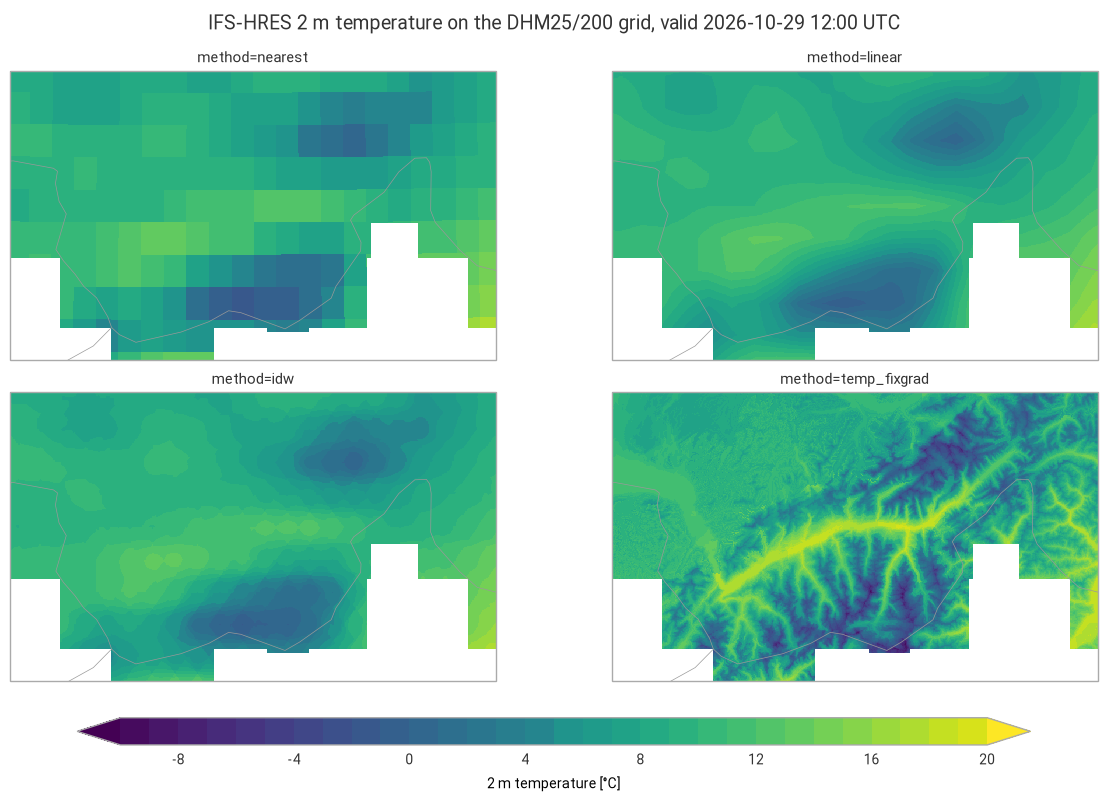

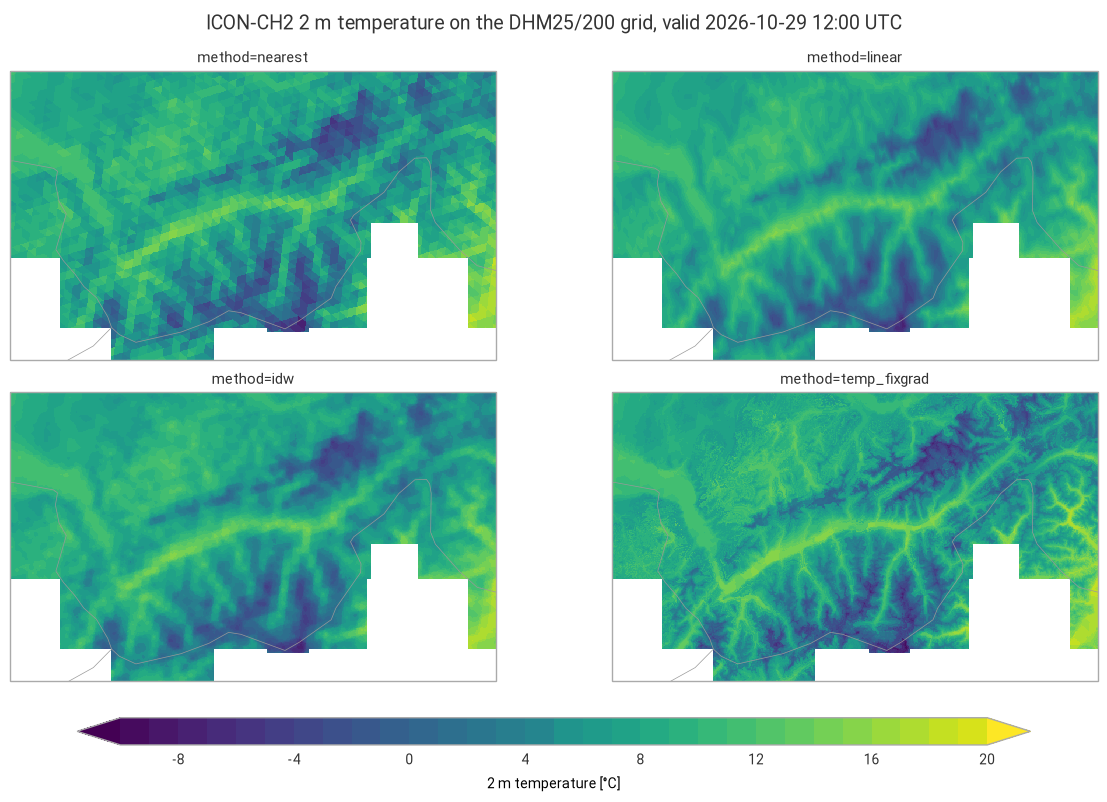

In [6]:
lv03 = ccrs.epsg(21781)
t_min = min(float(res[m]["T_2M"].min()) for res in results.values() for m in METHODS)
t_max = max(float(res[m]["T_2M"].max()) for res in results.values() for m in METHODS)
style = ekp.styles.Style(
    levels=np.arange(np.floor(t_min), np.ceil(t_max) + 1, 1), colors="viridis", extend="both", units="°C"
)

for name, res in results.items():
    fig = ekp.Figure(rows=2, columns=2, figsize=(12, 7.5), crs=lv03)
    for i, label in enumerate(METHODS):
        out = res[label]
        subplot = fig.add_map(i // 2, i % 2)
        subplot.pcolormesh(out["T_2M"].squeeze().values, x=out.x.values, y=out.y.values, style=style, transform=lv03)
        subplot.title(f"method={label}")
    fig.borders()
    fig.legend(label="2 m temperature [°C]")
    fig.title(f"{name} 2 m temperature on the DHM25/200 grid, valid {valid_time:%Y-%m-%d %H:%M} UTC")
    fig.show()

## Performance benchmark

The first call includes building the neighbour search structures and reprojecting the coordinates,
which `grid_process` caches. Subsequent calls on the same grids (e.g. for other variables or runs) reuse
them: their runtime is the mean ± standard deviation over 5 repetitions.

In [7]:
def benchmark(
    func: Callable[..., xr.Dataset],
    data: xr.Dataset,
    target: gpd.GeoDataFrame | xr.Dataset,
    methods: dict[str, dict[str, Any]],
    first_call_times: dict[str, float],
    repeat: int = 5,
) -> pd.DataFrame:
    """Runtime of the first call and mean ± standard deviation of the subsequent calls of each method."""
    rows: dict[str, dict[str, Any]] = {}
    for method, kw in methods.items():
        times = np.array(timeit.repeat(partial(func, data, target, **kw), number=1, repeat=repeat))
        rows[method] = {
            "first call [s]": f"{first_call_times[method]:.3f}",
            "subsequent calls [s]": f"{times.mean():.3f} ± {times.std():.3f}",
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("method")


print(f"destination grid: {dst_grid.y.size} × {dst_grid.x.size} cells")
# one column group per model; the try_reg=False rows only exist for the regular IFS grid
tables = {name: benchmark(gri.interp2grid, ds, dst_grid, runs[name], first_call[name]) for name, ds in models.items()}
pd.concat(tables, axis=1).fillna("–")

destination grid: 496 × 833 cells


IFS-HRES                            ICON-CH2  \
                        first call [s] subsequent calls [s] first call [s]   
method                                                                       
nearest                          0.309        0.053 ± 0.002          0.157   
nearest (try_reg=False)          0.164        0.100 ± 0.006              –   
linear                           0.083        0.067 ± 0.001          0.155   
linear (try_reg=False)           0.117        0.105 ± 0.000              –   
idw                              0.200        0.132 ± 0.007          0.238   
temp_fixgrad                     0.650        0.380 ± 0.061          0.611   

                                              
                        subsequent calls [s]  
method                                        
nearest                        0.095 ± 0.001  
nearest (try_reg=False)                    –  
linear                         0.139 ± 0.002  
linear (try_reg=False)                     –  
idw                            0.131 ± 0.002  
temp_fixgrad                   0.368 ± 0.010

## Takeaways

- With IFS-HRES (9 km), `nearest` shows the source grid boxes. `linear` and `idw` are smooth, but like
  the model they ignore the terrain at 200 m: the Rhône valley gets the temperature of a much higher
  model altitude, and the summits of a much lower one.
- `temp_fixgrad` restores the terrain structure by correcting with the altitude difference between the
  source grid point and the 200 m grid: warmer valleys, colder summits. ICON-CH2 (2 km) already
  resolves the main valleys, so its correction is smaller.
- The fixed lapse rate (`grad`, 6 K/km by default) is a simplification and cannot reproduce
  temperature inversions.
- Every method regrids both models to the 413 000 cells of the destination grid in well under a
  second. `temp_fixgrad` is the most expensive.
- On the regular IFS grid, the regular path (`try_reg=True`, the default) and the generic path
  (`try_reg=False`) of `nearest` select the same source grid point, except for a handful of destination
  cells lying almost on the boundary between two source grid boxes, where the reprojection tips the
  choice. `linear` differs slightly everywhere: the regular path is bilinear, while the generic path
  interpolates linearly on a triangulation of the source grid points. Here the regular path is the
  faster one.